In [3]:
#Importing the libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
#Importing the csv file and displaying first few rows

data = pd.read_csv("/content/weather_data_analysis.csv")
print(data.head())

         Date  Temperature_C  Humidity_Percent  Precipitation_mm
0  2023-01-01           21.9              71.4               0.0
1  2023-01-02           19.7              56.0               0.0
2  2023-01-03           22.5              77.8              23.0
3  2023-01-04           25.6              71.6               0.0
4  2023-01-05           27.5              80.1               0.0


In [5]:
#Checking data types

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1096 non-null   object 
 1   Temperature_C     1088 non-null   float64
 2   Humidity_Percent  1089 non-null   float64
 3   Precipitation_mm  1090 non-null   float64
dtypes: float64(3), object(1)
memory usage: 34.4+ KB


In [6]:
#Data Cleaning

data.isnull().sum()

,0
Date,0
Temperature_C,8
Humidity_Percent,7
Precipitation_mm,6


In [7]:
#Replacing null values with mean of respective column
cleaned_data = data.fillna(data.mean(numeric_only=True))

In [8]:
cleaned_data.isnull().sum()

,0
Date,0
Temperature_C,0
Humidity_Percent,0
Precipitation_mm,0


In [9]:
cleaned_data["Date"] = pd.to_datetime(cleaned_data["Date"])

In [10]:
cleaned_data.dtypes

,0
Date,datetime64[ns]
Temperature_C,float64
Humidity_Percent,float64
Precipitation_mm,float64


In [11]:
#Descriptive Statistics with NumPy

temp_mean = np.mean(cleaned_data["Temperature_C"])
temp_median = np.median(cleaned_data["Temperature_C"])
temp_std = np.std(cleaned_data["Temperature_C"])
humi_mean = np.mean(cleaned_data["Humidity_Percent"])
humi_median = np.median(cleaned_data["Humidity_Percent"])
humi_std = np.std(cleaned_data["Humidity_Percent"])
prec_mean = np.mean(cleaned_data["Precipitation_mm"])
prec_median = np.median(cleaned_data["Precipitation_mm"])
prec_std = np.std(cleaned_data["Precipitation_mm"])

print("Temperature Mean : ", round(temp_mean, 2))
print("Temperature Median : ", round(temp_median, 2))
print("Temperature Std : ", round(temp_std, 2))
print("Humidity Mean : ", round(humi_mean, 2))
print("Humidity Median : ", round(humi_median, 2))
print("Humidity Std : ", round(humi_std, 2))
print("Precipitation Mean : ", round(prec_mean, 2))
print("Precipitation Median : ", round(prec_median, 2))
print("Precipitation Std : ", round(prec_std, 2))

Temperature Mean :  27.14
Temperature Median :  27.12
Temperature Std :  6.08
Humidity Mean :  68.17
Humidity Median :  68.17
Humidity Std :  8.69
Precipitation Mean :  4.48
Precipitation Median :  0.0
Precipitation Std :  12.64


In [12]:
#Monthly and Seasonal Analysis

monthly_data = cleaned_data.groupby(cleaned_data["Date"].dt.month).mean(numeric_only=True)
print(round(monthly_data, 2))

      Temperature_C  Humidity_Percent  Precipitation_mm
Date                                                   
1             20.84             72.44              2.52
2             23.48             70.66              3.17
3             26.25             68.61              1.87
4             30.12             65.58              3.28
5             32.79             65.14              4.07
6             34.39             64.51              4.77
7             33.35             64.83              7.80
8             30.88             66.06              7.82
9             27.35             67.30              8.14
10            24.34             70.01              1.28
11            21.68             70.84              4.58
12            20.04             72.10              4.40


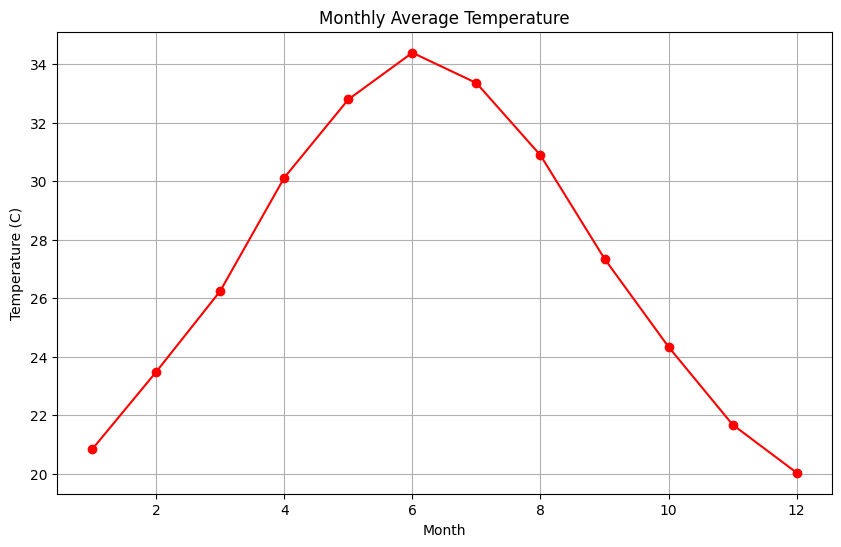

In [13]:
#Visualizations with Matplotlib

#Line Plot
monthly_temp = cleaned_data.groupby(cleaned_data["Date"].dt.month)["Temperature_C"].mean()

plt.figure(figsize=(10,6))
plt.plot(monthly_temp.index, monthly_temp.values, marker="o", color="red")

plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (C)")
plt.grid(True)
plt.show()

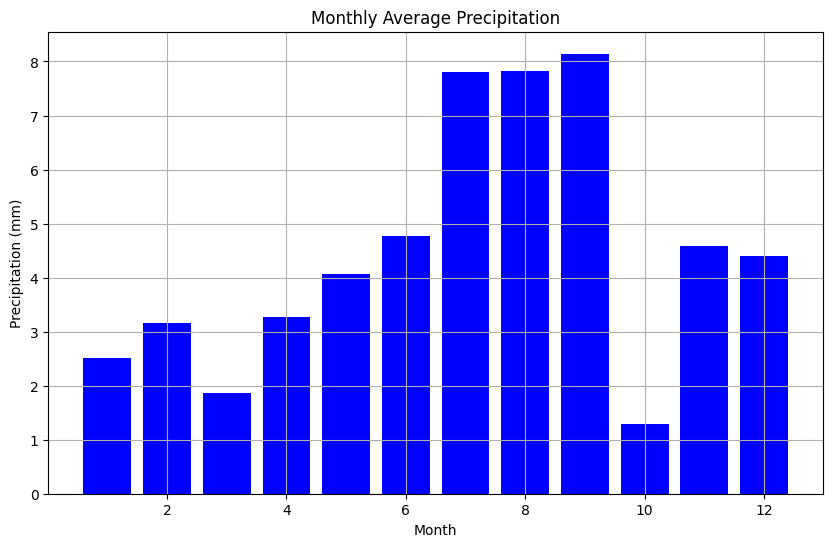

In [14]:
#Bar Chart
monthly_prec = cleaned_data.groupby(cleaned_data["Date"].dt.month)["Precipitation_mm"].mean()

plt.figure(figsize=(10,6))

plt.bar(monthly_prec.index, monthly_prec.values, color="blue")

plt.title("Monthly Average Precipitation")
plt.xlabel("Month")
plt.ylabel("Precipitation (mm)")
plt.grid(True)
plt.show()

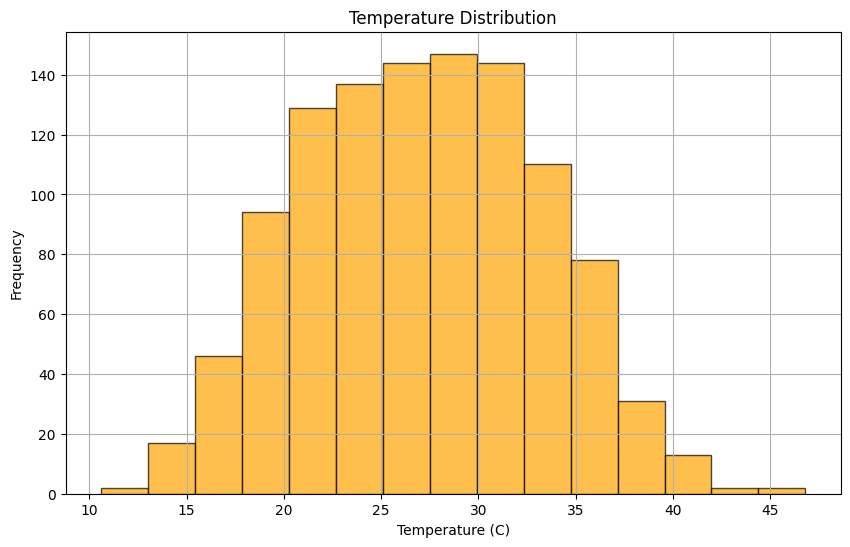

In [15]:
#Histogram

plt.figure(figsize=(10, 6))

plt.hist(cleaned_data["Temperature_C"], bins=15, color="orange", edgecolor="black", alpha=0.7)

plt.title("Temperature Distribution")
plt.xlabel("Temperature (C)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [16]:
#Identifying Extreme Weather

temp_threshold = 35.0
prec_threshold = 25.0

extreme_temp_days = cleaned_data[np.array(cleaned_data["Temperature_C"]) > temp_threshold]
extreme_prec_days = cleaned_data[np.array(cleaned_data["Precipitation_mm"]) > prec_threshold]

print("Extreme Temperature Days:")
print(extreme_temp_days[["Date", "Temperature_C"]])

print("\nExtreme Precipitation Days:")
print(extreme_prec_days[["Date", "Precipitation_mm"]])


Extreme Temperature Days:
          Date  Temperature_C
106 2023-04-17           46.8
113 2023-04-24           39.5
118 2023-04-29           35.4
122 2023-05-03           36.6
125 2023-05-06           39.6
..         ...            ...
953 2025-08-11           36.5
955 2025-08-13           35.1
961 2025-08-19           35.3
965 2025-08-23           35.2
967 2025-08-25           36.3

[111 rows x 2 columns]

Extreme Precipitation Days:
           Date  Precipitation_mm
24   2023-01-25              27.4
58   2023-02-28             132.8
63   2023-03-05              42.6
64   2023-03-06              53.5
105  2023-04-16              45.1
111  2023-04-22              32.8
117  2023-04-28              35.7
166  2023-06-16              42.1
196  2023-07-16              32.6
202  2023-07-22              37.4
218  2023-08-07              26.2
221  2023-08-10              33.4
224  2023-08-13              36.2
229  2023-08-18              45.0
236  2023-08-25              30.3
255  2023-09-13  